# CVRP methods overview (for group discussion)


## Summary of the methods I will use

| Step | Method | Role | In this notebook |
|---|---|---|---|
| 1. Construction | **Clarke-Wright Savings** | Main starting solution | Coded (section 3) |
| | Nearest Neighbor | Baseline and fallback if anything fails | Coded (section 3) |
| | Sweep | Candidate only. Needs coordinates, which our input does not give | Coded for comparison (section 3) |
| 2. Vehicle-limit repair | Cheapest-insertion repair | Fix the solution when routes exceed vehicles | Coded (section 4) |
| 3. Local search | **2-opt**, **relocate** | Improve routes with delta evaluation | Coded (section 5) |
| | Swap, Or-opt, 2-opt* | Extra moves to add next | Described only (section 5) |
| | Neighbour lists (20 to 40) | Speed-up for large instances | Described only (section 5) |
| 4. Metaheuristic | **ALNS** | Main search method for the final solver | Outline only (section 6) |
| | Simulated Annealing | Simpler fallback, and the acceptance rule inside ALNS | Coded (section 6) |
| 5. Output | Validate, then print | Never print an infeasible solution. Stop at about 85 to 90% of the time limit | Coded (section 7) |

Pipeline: **construction** -> **vehicle-limit repair** -> **local search** -> **metaheuristic** -> validate and print.

Run all cells from top to bottom. Needs Python 3.8+ and matplotlib.

In [ ]:
import math
import random
import matplotlib.pyplot as plt

## 1. Problem and scoring

A solution is feasible only if:
1. Every route starts and ends at the depot (vertex 0), with no 0 inside.
2. Every customer appears exactly once.
3. Total demand on each route is at most the capacity.
4. Number of non-empty routes is at most the number of vehicles.

An infeasible output scores 0.

Score per instance: `score = 1 / (0.5 * (2**max(0, t/L - 1) + c/b))`, where t is run time, L the limit, c our cost and b the best cost of all teams.

The table below shows how time and cost trade off on a large instance (L = 180 s).

In [6]:
def score(t, L, c, b):
    return 1 / (0.5 * (2 ** max(0, t / L - 1) + c / b))

L = 180
print('time    gap to best    score')
for t in [150, 180, 198, 225, 260]:
    for gap in [0.00, 0.02, 0.05]:
        print(f'{t:4d}s   {gap * 100:5.0f}%       {score(t, L, 1 + gap, 1):.3f}')
    print()

time    gap to best    score
 150s       0%       1.000
 150s       2%       0.990
 150s       5%       0.976

 180s       0%       1.000
 180s       2%       0.990
 180s       5%       0.976

 198s       0%       0.965
 198s       2%       0.956
 198s       5%       0.943

 225s       0%       0.914
 225s       2%       0.905
 225s       5%       0.893

 260s       0%       0.847
 260s       2%       0.840
 260s       5%       0.830



**Takeaways**
- Finishing early gives no bonus. Running 10% over L costs about as much as a 7% worse cost.
- So we should use most of the time (stop at about 85 to 90% of L) but never go over.
- Large instances carry 60% of the weight, so speed of the code on large n matters most.

## 2. Toy instance and helpers

Real instances give only demands and a distance matrix. Here we also generate x, y coordinates so we can **plot** routes (and run Sweep, see section 3).

Inside the code a route is a list of customers **without** the depot, for example `[3, 1, 7]`. The depot is added only when computing cost or printing (`0 3 1 7 0`).

In [7]:
def make_instance(n, seed, capacity=30, demand_max=10):
    rng = random.Random(seed)
    xy = [(50.0, 50.0)] + [(rng.uniform(0, 100), rng.uniform(0, 100)) for _ in range(n)]
    demand = [0] + [rng.randint(1, demand_max) for _ in range(n)]
    dist = [[math.dist(a, b) for b in xy] for a in xy]
    vehicles = math.ceil(sum(demand) / capacity) + 1   # one spare vehicle
    return xy, demand, dist, capacity, vehicles

xy, demand, dist, capacity, vehicles = make_instance(n=30, seed=42)
print('customers:', len(demand) - 1)
print('total demand:', sum(demand), ' capacity:', capacity, ' vehicles:', vehicles)

customers: 30
total demand: 174  capacity: 30  vehicles: 7


In [8]:
def route_cost(route, dist):
    if not route:
        return 0.0
    cost = dist[0][route[0]] + dist[route[-1]][0]
    for a, b in zip(route, route[1:]):
        cost += dist[a][b]
    return cost


def total_cost(routes, dist):
    return sum(route_cost(r, dist) for r in routes)


def is_feasible(routes, demand, capacity, vehicles):
    n = len(demand) - 1
    routes = [r for r in routes if r]
    if sorted(c for r in routes for c in r) != list(range(1, n + 1)):
        return False   # a customer is missing, repeated, or the depot is inside a route
    if any(sum(demand[c] for c in r) > capacity for r in routes):
        return False
    return len(routes) <= vehicles


def plot_routes(ax, routes, xy, title):
    for r in routes:
        path = [0] + r + [0]
        ax.plot([xy[i][0] for i in path], [xy[i][1] for i in path], '-o', markersize=3)
    ax.plot(xy[0][0], xy[0][1], 'ks', markersize=9)
    ax.set_title(title)
    ax.set_aspect('equal')

## 3. Construction methods

A construction method builds a first feasible solution quickly. Local search then improves it.

| Method | Idea | Cost to run | Notes |
|---|---|---|---|
| Nearest Neighbor | From the last stop, go to the closest customer that still fits. Start a new route when nothing fits. | O(n^2) | Simple baseline and fallback. Usually poor last legs back to the depot. |
| Clarke-Wright Savings | Start with one route per customer. Merge routes ending at i and j in order of saving `d(0,i) + d(0,j) - d(i,j)`. | O(n^2 log n) | Strong classic start. Savings list has n^2/2 entries, so for large n we may keep only near neighbours. |
| Sweep | Sort customers by angle around the depot, cut into routes when capacity is full. | O(n log n) | Needs **coordinates**. Our input has only a distance matrix, so we would need to recover coordinates (for example with MDS) or drop it. |

Other candidates (not coded here): route-first cluster-second (giant tour plus Split) and regret insertion.

In [9]:
def nearest_neighbor(dist, demand, capacity):
    unvisited = set(range(1, len(demand)))
    routes = []
    while unvisited:
        route, load, last = [], 0, 0
        while True:
            options = [c for c in unvisited if load + demand[c] <= capacity]
            if not options:
                break
            nxt = min(options, key=lambda c: dist[last][c])
            route.append(nxt)
            load += demand[nxt]
            unvisited.remove(nxt)
            last = nxt
        routes.append(route)
    return routes


def clarke_wright(dist, demand, capacity):
    n = len(demand) - 1
    routes = {i: [i] for i in range(1, n + 1)}     # route id -> customers
    route_of = {i: i for i in range(1, n + 1)}     # customer -> route id
    load = {i: demand[i] for i in range(1, n + 1)}

    savings = []
    for i in range(1, n + 1):
        for j in range(i + 1, n + 1):
            savings.append((dist[0][i] + dist[0][j] - dist[i][j], i, j))
    savings.sort(reverse=True)

    for s, i, j in savings:
        if s <= 0:
            break
        ri, rj = route_of[i], route_of[j]
        if ri == rj or load[ri] + load[rj] > capacity:
            continue
        a, b = routes[ri], routes[rj]
        # i must be at the end of a, and j at the start of b (routes can be flipped)
        if a[-1] != i:
            a.reverse()
        if b[0] != j:
            b.reverse()
        if a[-1] != i or b[0] != j:
            continue   # i or j is in the middle of its route
        routes[ri] = a + b
        load[ri] += load[rj]
        for c in b:
            route_of[c] = ri
        del routes[rj]
        del load[rj]
    return list(routes.values())


def sweep(xy, demand, capacity):
    x0, y0 = xy[0]
    order = sorted(range(1, len(xy)), key=lambda c: math.atan2(xy[c][1] - y0, xy[c][0] - x0))
    routes, route, load = [], [], 0
    for c in order:
        if load + demand[c] > capacity:
            routes.append(route)
            route, load = [], 0
        route.append(c)
        load += demand[c]
    if route:
        routes.append(route)
    return routes

Nearest Neighbor   cost  1158.81   routes 6   feasible True
Clarke-Wright      cost   744.10   routes 6   feasible True
Sweep              cost   891.68   routes 7   feasible True


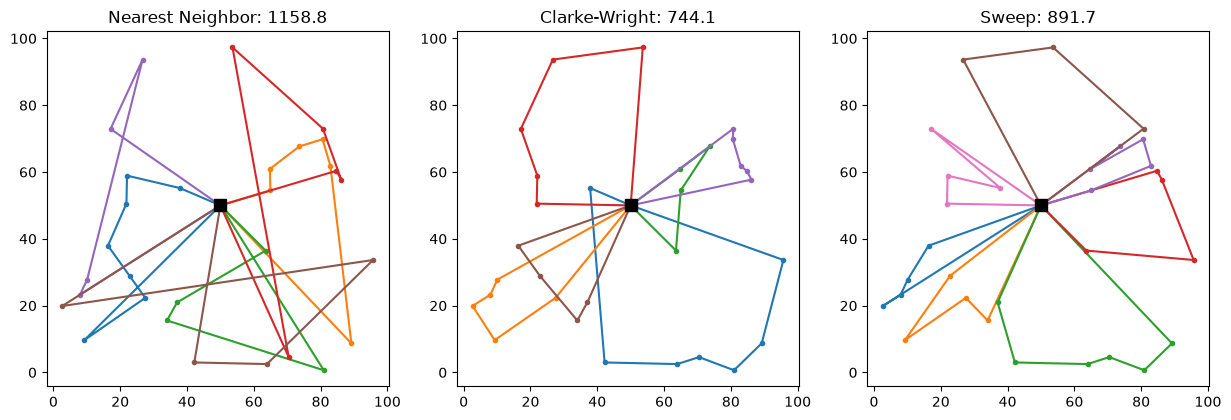

In [10]:
constructions = {
    'Nearest Neighbor': nearest_neighbor(dist, demand, capacity),
    'Clarke-Wright': clarke_wright(dist, demand, capacity),
    'Sweep': sweep(xy, demand, capacity),
}

results = {}   # method name -> cost, used in the final comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, routes) in zip(axes, constructions.items()):
    cost = total_cost(routes, dist)
    results[name] = cost
    ok = is_feasible(routes, demand, capacity, vehicles)
    print(f'{name:18s} cost {cost:8.2f}   routes {len(routes)}   feasible {ok}')
    plot_routes(ax, routes, xy, f'{name}: {cost:.1f}')
plt.show()

## 4. Vehicle-limit repair

None of the methods above looks at the vehicle limit. If a method makes more routes than vehicles, the solution is infeasible.

Simple repair: take the route with the smallest load, remove it, and insert each of its customers at the cheapest feasible position in another route. Repeat until the route count fits.

This can fail when the capacity is very tight (bin packing is hard). Then we need a stronger method, for example a first-fit-decreasing packing followed by local search.

The demo uses the tightest possible limit `ceil(total demand / capacity)`, which may not even be reachable.

In [11]:
def repair_vehicles(routes, dist, demand, capacity, vehicles):
    routes = [r[:] for r in routes if r]
    while len(routes) > vehicles:
        routes.sort(key=lambda r: sum(demand[c] for c in r))
        smallest = routes.pop(0)
        for c in smallest:
            best = None   # (extra cost, route, position)
            for r in routes:
                if sum(demand[x] for x in r) + demand[c] > capacity:
                    continue
                for pos in range(len(r) + 1):
                    prev = r[pos - 1] if pos > 0 else 0
                    nxt = r[pos] if pos < len(r) else 0
                    extra = dist[prev][c] + dist[c][nxt] - dist[prev][nxt]
                    if best is None or extra < best[0]:
                        best = (extra, r, pos)
            if best is None:
                return None   # no route has room for c
            best[1].insert(best[2], c)
    return routes


tight = math.ceil(sum(demand) / capacity)
print('Tight vehicle limit:', tight, '  (instance limit:', vehicles, ')')
for name, routes in constructions.items():
    fixed = repair_vehicles(routes, dist, demand, capacity, tight)
    if fixed is None:
        print(f'{name:18s} {len(routes)} routes -> repair failed')
    else:
        print(f'{name:18s} {len(routes)} routes -> {len(fixed)} routes, cost {total_cost(fixed, dist):.2f}')

Tight vehicle limit: 6   (instance limit: 7 )
Nearest Neighbor   6 routes -> 6 routes, cost 1158.81
Clarke-Wright      6 routes -> 6 routes, cost 744.10
Sweep              7 routes -> repair failed


## 5. Local search

Local search tries small changes and keeps any that lower the cost, until no change helps.

**Delta evaluation** is the key speed trick. We never recompute the whole cost. For example, 2-opt reverses the segment between b and c in `... a b ... c d ...`:

`delta = d(a,c) + d(b,d) - d(a,b) - d(c,d)`

That is 4 lookups instead of summing the whole route.

| Move | What it does | Coded here |
|---|---|---|
| 2-opt | Reverse a segment inside one route (removes crossings) | yes |
| Relocate | Move one customer to another route | yes |
| Swap | Exchange two customers between routes | no |
| Or-opt | Move a chain of 2 or 3 customers | no |
| 2-opt* | Swap the tails of two routes | no |

On large instances we only try moves between a customer and its 20 to 40 nearest neighbours (neighbour lists). That cuts each pass from O(n^2) to about O(n * k).

In [12]:
def two_opt(route, dist):
    r = [0] + route + [0]
    improved = True
    while improved:
        improved = False
        for i in range(1, len(r) - 2):
            for j in range(i + 1, len(r) - 1):
                a, b, c, d = r[i - 1], r[i], r[j], r[j + 1]
                delta = dist[a][c] + dist[b][d] - dist[a][b] - dist[c][d]
                if delta < -1e-9:
                    r[i:j + 1] = reversed(r[i:j + 1])
                    improved = True
    return r[1:-1]


def relocate(routes, dist, demand, capacity):
    routes = [r[:] for r in routes]
    loads = [sum(demand[c] for c in r) for r in routes]
    improved = True
    while improved:
        improved = False
        for ri, r in enumerate(routes):
            for pos in range(len(r)):
                c = r[pos]
                prev = r[pos - 1] if pos > 0 else 0
                nxt = r[pos + 1] if pos < len(r) - 1 else 0
                saved = dist[prev][c] + dist[c][nxt] - dist[prev][nxt]   # gain from removing c
                best = None   # (extra cost, route index, position)
                for rj, s in enumerate(routes):
                    if rj == ri or loads[rj] + demand[c] > capacity:
                        continue
                    for k in range(len(s) + 1):
                        p = s[k - 1] if k > 0 else 0
                        q = s[k] if k < len(s) else 0
                        extra = dist[p][c] + dist[c][q] - dist[p][q]
                        if extra - saved < -1e-9 and (best is None or extra < best[0]):
                            best = (extra, rj, k)
                if best is not None:
                    _, rj, k = best
                    r.pop(pos)
                    routes[rj].insert(k, c)
                    loads[ri] -= demand[c]
                    loads[rj] += demand[c]
                    improved = True
                    break   # route changed, start scanning again
            if improved:
                break
    return [r for r in routes if r]


def local_search(routes, dist, demand, capacity):
    best = total_cost(routes, dist)
    while True:
        routes = relocate(routes, dist, demand, capacity)
        routes = [two_opt(r, dist) for r in routes]
        cost = total_cost(routes, dist)
        if cost > best - 1e-9:
            return routes
        best = cost

Nearest Neighbor    1158.81 ->   956.39   (17.5% better)   feasible True
Clarke-Wright        744.10 ->   744.10   (0.0% better)   feasible True
Sweep                891.68 ->   808.99   (9.3% better)   feasible True


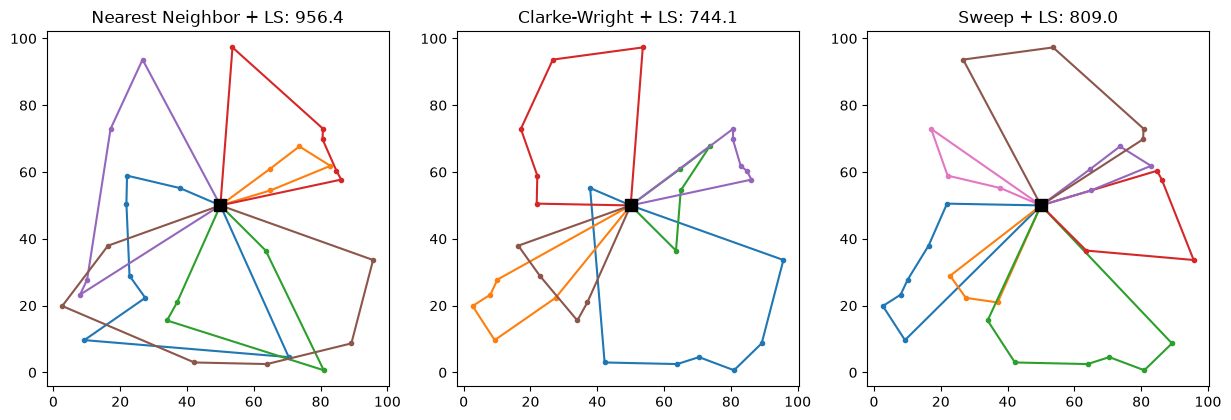

In [13]:
ls_routes = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, routes) in zip(axes, constructions.items()):
    improved = local_search(routes, dist, demand, capacity)
    ls_routes[name] = improved
    before, after = total_cost(routes, dist), total_cost(improved, dist)
    results[name + ' + LS'] = after
    ok = is_feasible(improved, demand, capacity, vehicles)
    print(f'{name:18s} {before:8.2f} -> {after:8.2f}   ({(before - after) / before * 100:.1f}% better)   feasible {ok}')
    plot_routes(ax, improved, xy, f'{name} + LS: {after:.1f}')
plt.show()

## 6. Metaheuristic

Local search stops at a local optimum. A metaheuristic keeps searching by sometimes accepting worse solutions.

### Simulated Annealing (simple fallback, coded here)

- Pick a random move (relocate a customer, or reverse a segment).
- If it is better, accept it. If it is worse by `delta`, accept it with probability `exp(-delta / T)`.
- The temperature T starts high (accepts many bad moves) and cools down (accepts almost none).
- Always remember the best feasible solution seen.

Here it runs a fixed number of iterations so the same seed gives the same result. The real solver will stop on time (about 85 to 90% of L). To keep the demo short it recomputes the full cost, while the real solver should use delta evaluation.

In [14]:
def simulated_annealing(routes, dist, demand, capacity, iterations=20000, seed=0, t_start=10.0, t_end=0.01):
    rng = random.Random(seed)
    cur = [r[:] for r in routes]
    cur_cost = total_cost(cur, dist)
    best, best_cost = [r[:] for r in cur], cur_cost
    history = []
    for it in range(iterations):
        temp = t_start * (t_end / t_start) ** (it / iterations)
        new = [r[:] for r in cur]
        ri = rng.randrange(len(new))
        if rng.random() < 0.5:
            # relocate a random customer to a random position
            if not new[ri]:
                continue
            c = new[ri].pop(rng.randrange(len(new[ri])))
            rj = rng.randrange(len(new))
            if rj != ri and sum(demand[x] for x in new[rj]) + demand[c] > capacity:
                continue   # would break capacity, skip this move
            new[rj].insert(rng.randint(0, len(new[rj])), c)
        else:
            # reverse a random segment inside one route
            if len(new[ri]) < 2:
                continue
            i, j = sorted(rng.sample(range(len(new[ri])), 2))
            new[ri][i:j + 1] = reversed(new[ri][i:j + 1])
        new_cost = total_cost(new, dist)
        delta = new_cost - cur_cost
        if delta < 0 or rng.random() < math.exp(-delta / temp):
            cur, cur_cost = new, new_cost
            if cur_cost < best_cost - 1e-9:
                best, best_cost = [r[:] for r in cur], cur_cost
        history.append(best_cost)
    return [r for r in best if r], best_cost, history

Starting SA from: Clarke-Wright + LS (744.10)
After SA: 744.10   feasible True


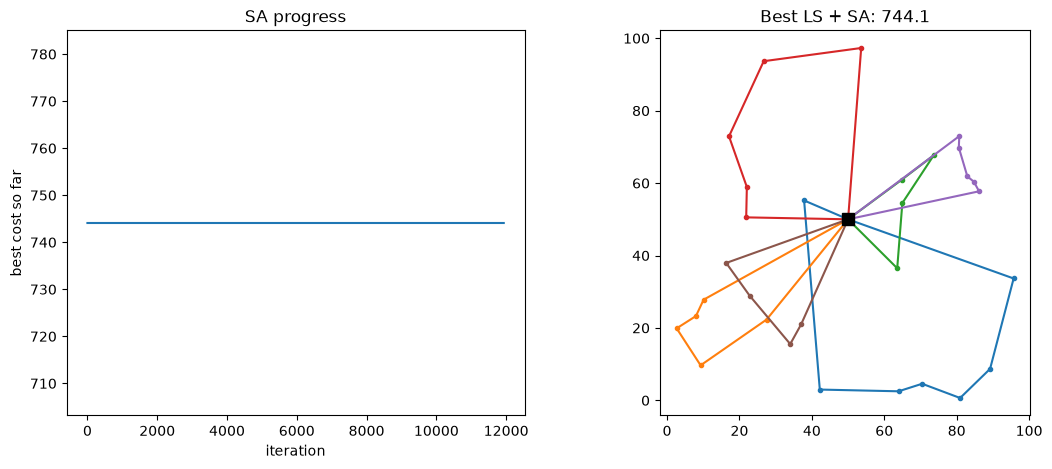

In [15]:
start_name = min(ls_routes, key=lambda k: total_cost(ls_routes[k], dist))
print('Starting SA from:', start_name + ' + LS', f'({total_cost(ls_routes[start_name], dist):.2f})')

sa_routes, sa_cost, history = simulated_annealing(ls_routes[start_name], dist, demand, capacity, seed=0)
results['Best LS + SA'] = sa_cost
print(f'After SA: {sa_cost:.2f}   feasible {is_feasible(sa_routes, demand, capacity, vehicles)}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.plot(history)
ax1.set_xlabel('iteration')
ax1.set_ylabel('best cost so far')
ax1.set_title('SA progress')
plot_routes(ax2, sa_routes, xy, f'Best LS + SA: {sa_cost:.1f}')
plt.show()

### ALNS (planned main method, outline only)

Adaptive Large Neighbourhood Search repeats **destroy and repair** on the current solution:

1. **Destroy**: remove 10 to 30% of customers with one of these operators:
   - random removal
   - worst removal (customers that add the most cost)
   - related removal (customers close to each other, Shaw removal)
   - route removal (empty a whole route, helps reduce vehicles)
2. **Repair**: put them back with greedy insertion (cheapest position) or regret insertion (first insert the customer that would lose most if it waited).
3. Run a quick local search on the result.
4. **Accept** with the same SA rule as above.
5. **Adapt**: operators that often find better solutions get picked more often.

ALNS makes larger jumps than SA, so it escapes local optima better on large instances. It reuses everything above: insertion from the repair step, local search moves and SA acceptance.

## 7. Comparison and final output

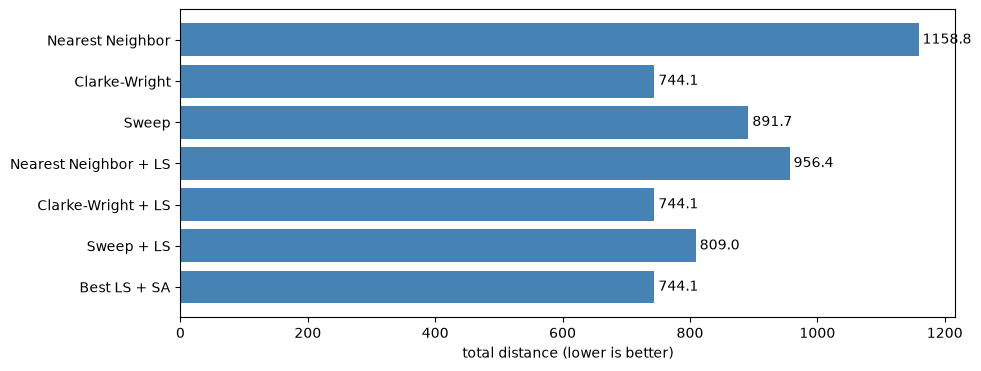

In [16]:
names = list(results)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(names, [results[k] for k in names], color='steelblue')
ax.invert_yaxis()
ax.set_xlabel('total distance (lower is better)')
for i, k in enumerate(names):
    ax.text(results[k], i, f' {results[k]:.1f}', va='center')
plt.show()

In [17]:
# Golden rule: validate before printing. Output uses the grader's format.
final = [r for r in sa_routes if r]
assert is_feasible(final, demand, capacity, vehicles)
print(f'{total_cost(final, dist):.6f}')
for r in final:
    print(' '.join(str(c) for c in [0] + r + [0]))

744.096617
0 13 4 10 21 1 5 18 0
0 2 14 7 23 24 0
0 28 3 8 25 0
0 6 9 29 27 17 0
0 16 11 19 15 20 0
0 26 12 22 30 0
